# Quantum Gates: States, Bloch Sphere, Gate Sequences, and Bell States

This cleaned notebook retains the main examples from the original `Quantum gates.html`: the initial one-qubit state, Pauli matrices, Hadamard (`H`) and phase (`T`) gates, the four sequences `HTH`, `HTT`, `THT`, `TTH`, Bloch-sphere trajectories, and a two-qubit Bell state. It removes duplicate debugging experiments and uses NumPy arrays for reliable numerical calculations.

**Convention:** a matrix product such as `H @ T @ T @ psi0` applies the rightmost gate first. Thus the temporal order for `HTT` in that product is `T`, then `T`, then `H`.

If plotting fails with a NumPy/Matplotlib binary-compatibility error, run the installation cell below and then restart the Jupyter kernel before running the notebook from the top.

## 0. Environment check and plotting compatibility

In [1]:
%pip install --upgrade matplotlib


  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/66/54/91fe3fdfa29100b4668cbf9721577a10acde6e009694618230e4e7a97527/matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     --------------- ------------------------ 30.7/80.3 kB ? eta -:--:--
     --------------- ------------------------ 30.7/80.3 kB ? eta -:--:--
     --------------- ------------------------ 30.7/80.3 kB ? eta -:--:--
     ------------------- ------------------ 41.0/80.3 kB 196.9 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 319.7 kB/s eta 0:00:00
  Obtaining dependency information for fonttools>=4.28.2 from https://files.pythonhosted.org/packages/46/87/4ba592099172764aa56e66919b0c3ddaf944c775433e806e36e165062095/fonttools-4.68.0-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ---------------- ------------------

NumPy: 2.4.6
Matplotlib: 3.11.2


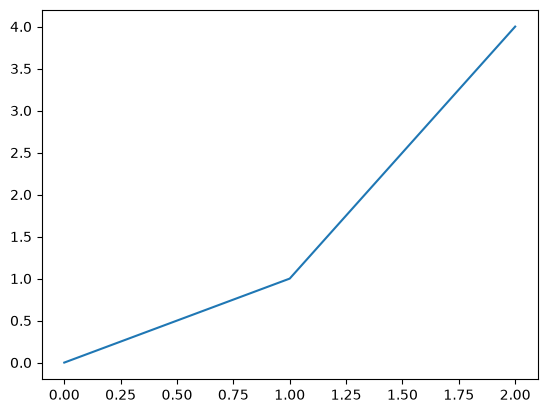

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

plt.plot([0, 1, 2], [0, 1, 4])
plt.show()

In [2]:
import sys
import numpy as np

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)

try:
    import matplotlib
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D  # registers 3-D projection
    print("Matplotlib:", matplotlib.__version__)
except Exception as exc:
    print("Matplotlib could not be imported:", repr(exc))
    print("In a notebook cell, run: %pip install --upgrade matplotlib")
    print("Then restart the kernel and run all cells again.")

Python: 3.11.4
NumPy: 2.4.6
Matplotlib: 3.11.2


### If Matplotlib is incompatible

Only run this if the previous cell reports a Matplotlib import error:

```python
%pip install --upgrade matplotlib
```

After installation, **restart the kernel**. If NumPy itself was just upgraded, restarting is especially important because already-loaded binary libraries remain in memory.

## 1. Initial state, gates, and Pauli matrices

In [3]:
from numpy import pi

# Original initial state:
# |psi0> = cos(pi/12)|0> + exp(i*pi/3) sin(pi/12)|1>
psi0 = np.array([
    np.cos(pi / 12),
    np.exp(1j * pi / 3) * np.sin(pi / 12)
], dtype=complex)

# Single-qubit gates
I2 = np.eye(2, dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
T = np.array([[1, 0], [0, np.exp(1j * pi / 4)]], dtype=complex)

# Pauli matrices
sx = np.array([[0, 1], [1, 0]], dtype=complex)
sy = np.array([[0, -1j], [1j, 0]], dtype=complex)
sz = np.array([[1, 0], [0, -1]], dtype=complex)

print("Initial state |psi0>:", np.round(psi0, 6))
print("Norm squared:", float(np.vdot(psi0, psi0).real))
print("H is unitary:", np.allclose(H.conj().T @ H, I2))
print("T is unitary:", np.allclose(T.conj().T @ T, I2))

Initial state |psi0>: [0.965926+0.j       0.12941 +0.224144j]
Norm squared: 1.0
H is unitary: True
T is unitary: True


## 2. Bloch vector and the four original gate-sequence examples

For a normalized pure state, the Bloch coordinates are the expectation values of the Pauli matrices: `r = (<sx>, <sy>, <sz>)`. In the original matrix products, the rightmost gate acts first.

In [4]:
def bloch(state):
    """Return the real Bloch vector [<X>, <Y>, <Z>] for a statevector."""
    state = np.asarray(state, dtype=complex).reshape(-1)
    norm = np.linalg.norm(state)
    if not np.isclose(norm, 1.0, atol=1e-10):
        raise ValueError(f"State must be normalized; norm={norm}")
    values = [np.vdot(state, P @ state) for P in (sx, sy, sz)]
    return np.real_if_close(values).astype(float)

print("Initial Bloch vector:", np.round(bloch(psi0), 6))
# Expected: [1/4, sqrt(3)/4, sqrt(3)/2]

# Preserve the original operator-product definitions.
sequence_products = {
    "HTH": H @ T @ H,
    "HTT": H @ T @ T,
    "THT": T @ H @ T,
    "TTH": T @ T @ H,
}

sequence_states = {name: U @ psi0 for name, U in sequence_products.items()}
sequence_bloch = {name: bloch(state) for name, state in sequence_states.items()}

for name in sequence_products:
    print(f"{name}: state = {np.round(sequence_states[name], 6)}")
    print(f"     Bloch = {np.round(sequence_bloch[name], 6)}")

Initial Bloch vector: [0.25     0.433013 0.866025]
HTH: state = [0.922668+0.328578j 0.172668-0.104434j]
     Bloch = [ 0.25     -0.306186  0.918559]
HTT: state = [0.524519+0.091506j 0.841506-0.091506j]
     Bloch = [ 0.866025 -0.25     -0.433013]
THT: state = [0.635646+0.176777j 0.641457+0.391457j]
     Bloch = [ 0.953879  0.270866 -0.12941 ]
TTH: state = [0.774519+0.158494j 0.158494+0.591506j]
     Bloch = [0.433013 0.866025 0.25    ]


## 3. Plot the initial state and final states on the Bloch sphere

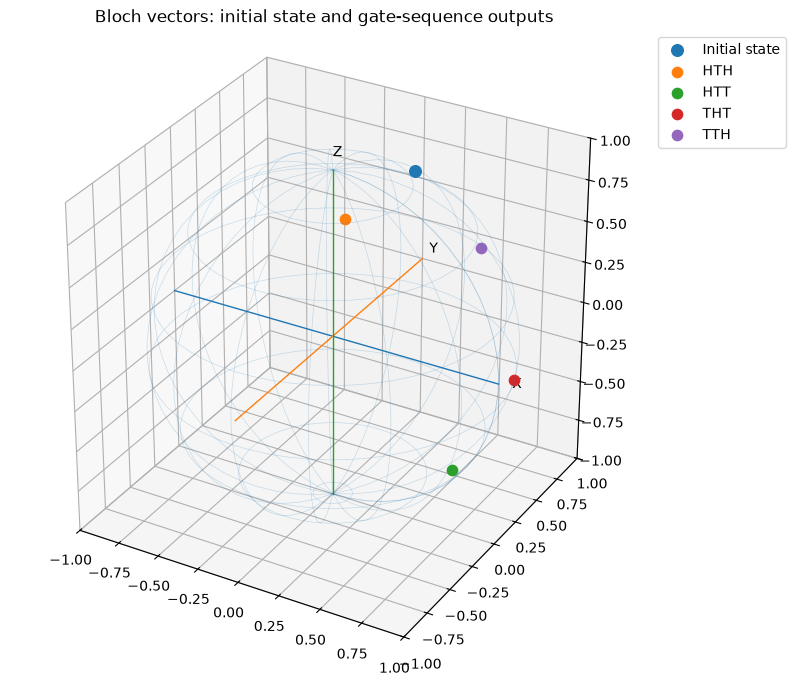

In [5]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# Sphere wireframe
u = np.linspace(0, 2*pi, 60)
v = np.linspace(0, pi, 30)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones_like(u), np.cos(v))
ax.plot_wireframe(xs, ys, zs, rstride=4, cstride=4, linewidth=0.5, alpha=0.22)

# Coordinate axes
ax.plot([-1, 1], [0, 0], [0, 0], linewidth=1)
ax.plot([0, 0], [-1, 1], [0, 0], linewidth=1)
ax.plot([0, 0], [0, 0], [-1, 1], linewidth=1)
ax.text(1.08, 0, 0, "X")
ax.text(0, 1.08, 0, "Y")
ax.text(0, 0, 1.08, "Z")

r0 = bloch(psi0)
ax.scatter(*r0, s=70, label="Initial state")
for name, r in sequence_bloch.items():
    ax.scatter(*r, s=55, label=name)

ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))
ax.set_box_aspect((1, 1, 1))
ax.set_title("Bloch vectors: initial state and gate-sequence outputs")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

## 4. Correct continuous Bloch-sphere trajectories

A straight interpolation between two statevectors or gate matrices is generally **not** a physical unitary evolution. Instead, draw each gate as a rotation on the Bloch sphere.

- `T = diag(1, exp(i pi/4))` corresponds, up to a global phase, to a rotation about the z-axis by `pi/4`.
- The Hadamard gate corresponds, up to a global phase, to a rotation by **pi** about the axis `(x + z)/sqrt(2)`. A `pi/2` rotation is not the correct Hadamard Bloch-sphere rotation.

The paths below follow the temporal gate order implied by the original operator products (rightmost gate first).

In [6]:
def rotate_vector(r, axis, angle):
    """Rodrigues rotation of a 3-vector around a unit axis."""
    axis = np.asarray(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    r = np.asarray(r, dtype=float)
    return (r*np.cos(angle)
            + np.cross(axis, r)*np.sin(angle)
            + axis*np.dot(axis, r)*(1-np.cos(angle)))

H_AXIS = np.array([1.0, 0.0, 1.0]) / np.sqrt(2)

def apply_bloch_gate(r, gate_name, fraction=1.0):
    """Apply a fractional Bloch rotation for visualization of a gate path."""
    if gate_name == "H":
        return rotate_vector(r, H_AXIS, pi*fraction)
    if gate_name == "T":
        return rotate_vector(r, np.array([0.0, 0.0, 1.0]), (pi/4)*fraction)
    raise ValueError("Supported gates are H and T")

# For U = G1 @ G2 @ G3, temporal order is G3, G2, G1.
temporal_sequences = {name: list(name[::-1]) for name in sequence_products}

def trajectory_for(sequence, r_start, points_per_gate=50):
    """Sample a continuous Bloch rotation for each gate in temporal order."""
    points = [np.asarray(r_start, dtype=float)]
    current = np.asarray(r_start, dtype=float)
    for gate_name in sequence:
        for fraction in np.linspace(0, 1, points_per_gate+1)[1:]:
            points.append(apply_bloch_gate(current, gate_name, fraction))
        current = apply_bloch_gate(current, gate_name, 1.0)
    return np.asarray(points)

trajectories = {
    name: trajectory_for(temporal_sequences[name], bloch(psi0))
    for name in sequence_products
}

# Validate the trajectory endpoint against the statevector calculation.
for name, path in trajectories.items():
    assert np.allclose(path[-1], sequence_bloch[name], atol=1e-8), (
        name, path[-1], sequence_bloch[name]
    )
print("All trajectory endpoints agree with the matrix calculations.")

All trajectory endpoints agree with the matrix calculations.


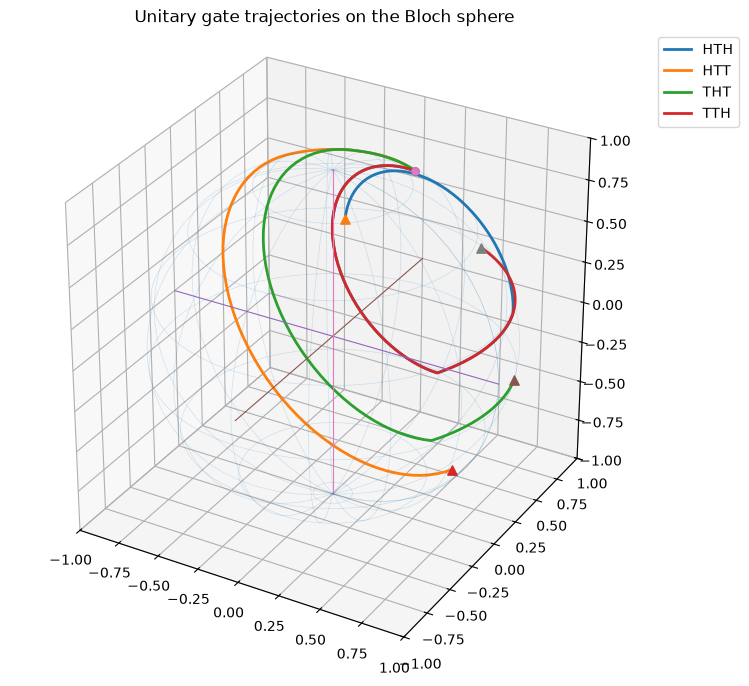

In [7]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_wireframe(xs, ys, zs, rstride=4, cstride=4, linewidth=0.5, alpha=0.18)

# Draw full trajectories; use the initial and final markers for orientation.
for name, path in trajectories.items():
    ax.plot(path[:, 0], path[:, 1], path[:, 2], linewidth=2, label=name)
    ax.scatter(*path[0], s=25, marker="o")
    ax.scatter(*path[-1], s=45, marker="^")

ax.plot([-1, 1], [0, 0], [0, 0], linewidth=0.8)
ax.plot([0, 0], [-1, 1], [0, 0], linewidth=0.8)
ax.plot([0, 0], [0, 0], [-1, 1], linewidth=0.8)
ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))
ax.set_box_aspect((1, 1, 1))
ax.set_title("Unitary gate trajectories on the Bloch sphere")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

## 5. Verify gate actions and probabilities

In [ ]:
def probabilities(state):
    """Return clean Python floats for computational-basis probabilities."""
    return np.abs(np.asarray(state, dtype=complex))**2

for name, state in sequence_states.items():
    p = probabilities(state)
    print(f"{name}: probabilities =", np.round(p, 6),
          "sum =", float(p.sum()))
    assert np.isclose(p.sum(), 1.0)

## 6. Qiskit: one-qubit Hadamard example

In [ ]:
try:
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector

    print("Qiskit:", qiskit.__version__)
    qc = QuantumCircuit(1)
    qc.h(0)
    print(qc.draw(output="text"))
    state_h = Statevector.from_instruction(qc)
    print("Statevector:", state_h.data)
    probs_h = {str(k): float(v) for k, v in state_h.probabilities_dict().items()}
    print("Probabilities:", probs_h)
    assert np.allclose(state_h.data, np.array([1, 1])/np.sqrt(2))
except ImportError as exc:
    print("Qiskit is not installed in this environment:", exc)
    print("Install with: %pip install qiskit")

## 7. Qiskit: Bell-state preparation and verification

The circuit `H` on qubit 0 followed by `CX(0, 1)` prepares the Bell state `( |00> + |11> ) / sqrt(2)`. Qiskit displays the statevector in computational-basis order `|00>, |01>, |10>, |11>` for this two-qubit example.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

bell_state = Statevector.from_instruction(bell)
bell_probs = {str(k): float(v) for k, v in bell_state.probabilities_dict().items()}

print(bell.draw(output="text"))
print("Statevector:", np.round(bell_state.data, 6))
print("Probabilities:", bell_probs)

expected_bell = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
assert np.allclose(bell_state.data, expected_bell)
assert np.isclose(bell_probs.get("00", 0.0), 0.5)
assert np.isclose(bell_probs.get("11", 0.0), 0.5)
print("Bell-state checks passed.")

## 8. Summary and interpretation

- The original initial state is normalized and has Bloch vector `(1/4, sqrt(3)/4, sqrt(3)/2)`.
- `H`, `T`, and the Pauli matrices are defined explicitly and checked numerically.
- The four original operator products are retained, with the rightmost-first convention stated clearly.
- Bloch paths are generated using unitary rotations, not linear interpolation of matrices.
- The Hadamard Bloch rotation angle is `pi`, while the T gate rotation angle is `pi/4` about z.
- The Qiskit Bell-state circuit is checked against the expected statevector and probabilities.

**Troubleshooting note:** if `Statevector.from_instruction` or Matplotlib fails after changing packages, restart the kernel and run all cells from the beginning. Avoid upgrading NumPy while other cells are running.